In [10]:
# Task 1 — Residuals by hand
# Expected file: titanic.csv in the same folder as this notebook.

import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_squared_error, accuracy_score, roc_auc_score,
    log_loss, precision_score, recall_score
)
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.base import clone
import xgboost
from xgboost import XGBClassifier


RANDOM_STATE = 42
DATA_PATH = "titanic.csv"

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip().str.lower()

# Normalize common Titanic column-name variants.
rename_map = {
    "passengerclass": "pclass",
    "passenger_class": "pclass",
    "survived": "survived",
    "sex": "sex",
    "age": "age",
    "siblings/spouses aboard": "sibsp",
    "sibsp": "sibsp",
    "parents/children aboard": "parch",
    "parch": "parch",
    "fare": "fare",
}
df = df.rename(columns={c: rename_map[c] for c in df.columns if c in rename_map})

required = ["pclass", "sex", "age", "sibsp", "parch", "fare", "survived"]
missing_cols = [c for c in required if c not in df.columns]
if missing_cols:
    raise ValueError(
        f"Missing required columns: {missing_cols}. "
        "Check that titanic.csv has the columns pclass, sex, age, sibsp, parch, fare, survived."
    )

# Create numeric sex_male; accepts common values such as male/female.
sex_text = df["sex"].astype(str).str.strip().str.lower()
df["sex_male"] = sex_text.map({"male": 1, "female": 0, "m": 1, "f": 0})
if df["sex_male"].isna().any():
    raise ValueError("Some sex values could not be mapped to 0/1. Inspect df['sex'].unique().")

# Median age within pclass and sex groups, as required by the task sheet.
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex_male"])["age"].transform("median")
)
df["age"] = df["age"].fillna(df["age"].median())
df["fare"] = df["fare"].fillna(df["fare"].median())

features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
target = "survived"
X = df[features].astype(float)
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

baseline_value = y_train.mean()
baseline_prediction = np.full(len(y_train), baseline_value, dtype=float)
residuals = y_train.to_numpy() - baseline_prediction

print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")
print(f"Baseline prediction (mean of y_train): {baseline_value:.4f}")
print(f"Baseline training MSE: {mean_squared_error(y_train, baseline_prediction):.4f}")

residual_table = pd.DataFrame({
    "actual_survived": y_train.to_numpy()[:10],
    "baseline_prediction": baseline_prediction[:10],
    "residual_actual_minus_predicted": residuals[:10]
})
display(residual_table)

Training rows: 800 | Test rows: 200
Baseline prediction (mean of y_train): 0.4400
Baseline training MSE: 0.2464


,actual_survived,baseline_prediction,residual_actual_minus_predicted
0,0,0.44,-0.44
1,0,0.44,-0.44
2,1,0.44,0.56
3,0,0.44,-0.44
4,1,0.44,0.56
5,0,0.44,-0.44
6,1,0.44,0.56
7,0,0.44,-0.44
8,1,0.44,0.56
9,1,0.44,0.56


## Task 1 — Residuals by hand

**Logic:** The baseline predicts the mean of `y_train` for every passenger. A residual is `actual − predicted`, so it measures the error still left in each prediction. The baseline MSE is the average squared residual.

**Interpretation:** For an actual survivor (`1`), the residual is usually positive because the baseline mean is below 1. For a passenger who did not survive (`0`), it is usually negative because the baseline mean is above 0. The sign tells the direction of the correction needed.

**Look it up / think about it**
- Why is the mean a sensible constant baseline for this simplified squared-error exercise?
- Why does the residual represent the part of the prediction that is still unexplained?

**Expected output:** Baseline mean, baseline MSE, and a table of the first ten actual values and residuals. Values depend on the provided `titanic.csv`; they are intentionally calculated rather than fabricated.

Final training MSE: 0.1452
Hand-built booster test accuracy (threshold=0.5): 0.7750
Hand-built booster test ROC-AUC: 0.8833


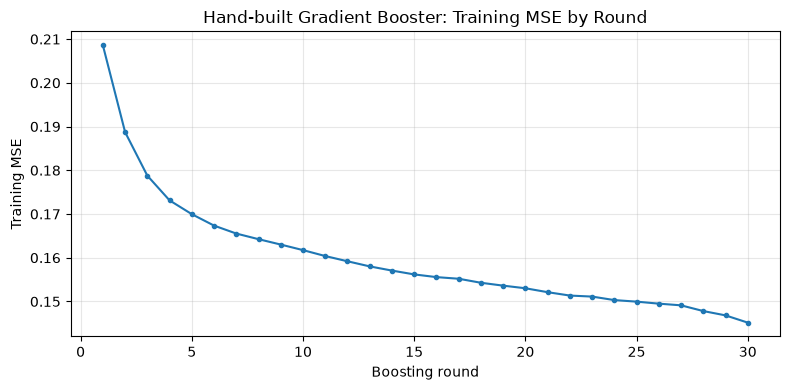

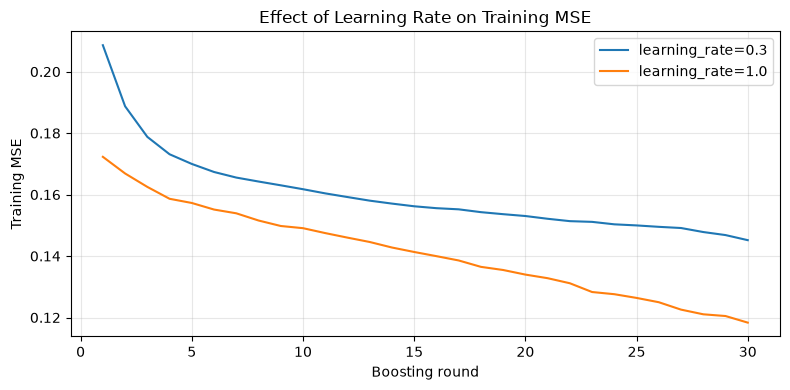

In [11]:
# Task 2 — Build a simple gradient booster with a loop
learning_rate = 0.3
n_rounds = 30
baseline_value = float(y_train.mean())
train_prediction = np.full(len(y_train), baseline_value, dtype=float)
trees = []
training_mse = []

for round_num in range(n_rounds):
    residual = y_train.to_numpy() - train_prediction
    tree = DecisionTreeRegressor(max_depth=2, random_state=RANDOM_STATE + round_num)
    tree.fit(X_train, residual)
    train_prediction += learning_rate * tree.predict(X_train)
    trees.append(tree)
    training_mse.append(mean_squared_error(y_train, train_prediction))

def predict_hand_booster(X_input):
    pred = np.full(len(X_input), baseline_value, dtype=float)
    for fitted_tree in trees:
        pred += learning_rate * fitted_tree.predict(X_input)
    return pred

test_prediction = predict_hand_booster(X_test)
# This hand-built model outputs regression-style scores. Threshold at 0.5 for accuracy.
test_labels = (test_prediction >= 0.5).astype(int)
print(f"Final training MSE: {training_mse[-1]:.4f}")
print(f"Hand-built booster test accuracy (threshold=0.5): {accuracy_score(y_test, test_labels):.4f}")
print(f"Hand-built booster test ROC-AUC: {roc_auc_score(y_test, test_prediction):.4f}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, n_rounds + 1), training_mse, marker="o", markersize=3)
plt.title("Hand-built Gradient Booster: Training MSE by Round")
plt.xlabel("Boosting round")
plt.ylabel("Training MSE")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Compare a deliberately large learning rate in the same simplified procedure.
pred_lr1 = np.full(len(y_train), baseline_value, dtype=float)
mse_lr1 = []
for round_num in range(n_rounds):
    resid = y_train.to_numpy() - pred_lr1
    t = DecisionTreeRegressor(max_depth=2, random_state=RANDOM_STATE + round_num)
    t.fit(X_train, resid)
    pred_lr1 += 1.0 * t.predict(X_train)
    mse_lr1.append(mean_squared_error(y_train, pred_lr1))

plt.figure(figsize=(8, 4))
plt.plot(range(1, n_rounds + 1), training_mse, label="learning_rate=0.3")
plt.plot(range(1, n_rounds + 1), mse_lr1, label="learning_rate=1.0")
plt.title("Effect of Learning Rate on Training MSE")
plt.xlabel("Boosting round")
plt.ylabel("Training MSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Task 2 — Build a gradient booster with a loop

**Logic:** Start from the training-target mean. At each round, calculate residuals, fit a depth-2 regression tree to them, then add `learning_rate × tree_prediction` to the current prediction. The stored trees are applied in the same order at prediction time.

**Why shallow trees can work together:** Each tree only needs to learn a small part of the remaining pattern. Many small corrections can combine into a more flexible ensemble.

**Learning rate:** A smaller rate makes more cautious updates. A rate of `1.0` applies each tree's full correction and can make learning less controlled.

**Look it up / think about it**
- Why can the training MSE curve fail to decrease monotonically in some boosting implementations?
- Why is this hand-built residual booster a simplified teaching version rather than the exact objective used by XGBoost for classification?

**Note:** The hand-built model fits raw residuals for demonstration. Its scores are not guaranteed to beat Random Forest or XGBoost.

In [12]:
# Task 3 — Random Forest vs XGBoost on the same split
from xgboost import XGBClassifier

rf_model = RandomForestClassifier(
    n_estimators=300, random_state=42, n_jobs=-1
)
xgb_300 = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    random_state=42
)

rf_model.fit(X_train, y_train)
xgb_300.fit(X_train, y_train)

def classification_metrics(fitted_model, model_name):
    train_prob = fitted_model.predict_proba(X_train)[:, 1]
    test_prob = fitted_model.predict_proba(X_test)[:, 1]
    test_pred = fitted_model.predict(X_test)
    return {
        "Model": model_name,
        "Train ROC-AUC": roc_auc_score(y_train, train_prob),
        "Test accuracy": accuracy_score(y_test, test_pred),
        "Test ROC-AUC": roc_auc_score(y_test, test_prob),
        "Train-test AUC gap": roc_auc_score(y_train, train_prob) - roc_auc_score(y_test, test_prob)
    }

comparison_03 = pd.DataFrame([
    classification_metrics(rf_model, "Random Forest"),
    classification_metrics(xgb_300, "XGBoost (300 trees)")
])
display(comparison_03.round(4))

,Model,Train ROC-AUC,Test accuracy,Test ROC-AUC,Train-test AUC gap
0,Random Forest,1.0000,0.740,0.8312,0.1688
1,XGBoost (300 trees),0.9519,0.735,0.8452,0.1067


## Task 3 — Bagging vs. boosting

**Logic:** Both models use the same cleaned features and the same stratified train/test split. Random Forest combines independently trained trees; XGBoost adds trees sequentially to improve the ensemble.

**How to conclude:** Compare test ROC-AUC to identify the better ranking performance on this split. Compare the train-test AUC gap to assess possible overfitting. A larger positive gap means the model performs substantially better on training data than on test data.

**Look it up / think about it**
- Which model has the higher test ROC-AUC in your table?
- Which model has the larger train-test gap?
- Why can a large gap be a warning sign even if the test score looks good?

**Important:** Do not claim one model is better until you inspect the table produced above.

Best iteration (zero-based): 91
Early-stopped test ROC-AUC: 0.8823
300-tree XGBoost test ROC-AUC: 0.8452


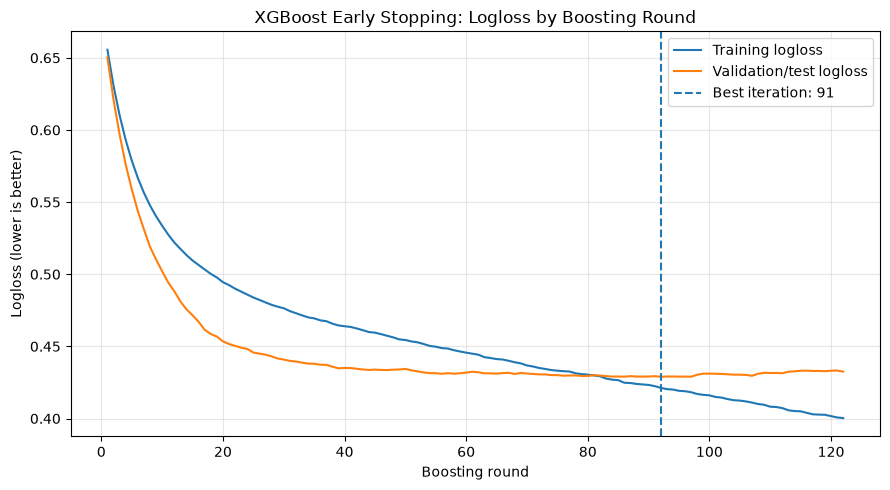

In [13]:
# Task 4 — Early stopping
# The task sheet uses X_test as the evaluation set for this teaching exercise.
# In real projects, use a separate validation set and keep the final test set untouched.

xgb_early = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    early_stopping_rounds=30,
    random_state=42
)
xgb_early.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=False
)

early_prob = xgb_early.predict_proba(X_test)[:, 1]
auc_early = roc_auc_score(y_test, early_prob)
auc_300 = roc_auc_score(y_test, xgb_300.predict_proba(X_test)[:, 1])

print("Best iteration (zero-based):", getattr(xgb_early, "best_iteration", "not exposed by this version"))
print(f"Early-stopped test ROC-AUC: {auc_early:.4f}")
print(f"300-tree XGBoost test ROC-AUC: {auc_300:.4f}")

evals = xgb_early.evals_result()
train_logloss = evals["validation_0"]["logloss"]
valid_logloss = evals["validation_1"]["logloss"]
rounds = np.arange(1, len(train_logloss) + 1)

plt.figure(figsize=(9, 5))
plt.plot(rounds, train_logloss, label="Training logloss")
plt.plot(rounds, valid_logloss, label="Validation/test logloss")
best_iter = getattr(xgb_early, "best_iteration", None)
if best_iter is not None:
    plt.axvline(best_iter + 1, linestyle="--", label=f"Best iteration: {best_iter}")
plt.title("XGBoost Early Stopping: Logloss by Boosting Round")
plt.xlabel("Boosting round")
plt.ylabel("Logloss (lower is better)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Task 4 — Early stopping

**Logic:** The model is allowed up to 1,000 boosting rounds, but training stops if the monitored validation logloss does not improve for 30 rounds. The best iteration is retained for prediction.

**How to interpret the plot:** Training logloss often continues to fall. If validation logloss falls and then rises, the model may be overfitting: it is improving its fit to training rows without improving generalization.

**Look it up / think about it**
- Did early stopping improve or worsen test ROC-AUC compared with the 300-tree model?
- Why is that result not necessarily a contradiction? The models are selected using logloss, while you are comparing ROC-AUC.
- What happens to training logloss after validation logloss turns upward?
- Why is using the test set for early stopping not good practice in a real project?

**Version note:** `best_iteration` is zero-based in XGBoost. The plot labels rounds starting at 1, so the vertical line uses `best_iteration + 1`.

In [14]:
# Task 5 — Learning-rate and tree-count trade-off
paired_settings = [
    (0.30, 50),
    (0.10, 150),
    (0.05, 300),
    (0.01, 1500),
]
broken_settings = [
    (0.01, 50),
    (0.30, 1500),
]

def fit_xgb_and_auc(lr, n_trees, seed=42):
    m = XGBClassifier(
        n_estimators=n_trees,
        learning_rate=lr,
        max_depth=3,
        eval_metric="logloss",
        random_state=seed
    )
    m.fit(X_train, y_train, verbose=False)
    auc = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
    return m, auc

rows = []
for lr, n_trees in paired_settings:
    fitted, auc = fit_xgb_and_auc(lr, n_trees)
    rows.append({"Learning rate": lr, "n_estimators": n_trees, "Test ROC-AUC": auc, "Group": "Paired"})

for lr, n_trees in broken_settings:
    fitted, auc = fit_xgb_and_auc(lr, n_trees)
    rows.append({"Learning rate": lr, "n_estimators": n_trees, "Test ROC-AUC": auc, "Group": "Broken pair"})

tradeoff_results = pd.DataFrame(rows)
display(tradeoff_results.round(4))

,Learning rate,n_estimators,Test ROC-AUC,Group
0,0.30,50,0.8616,Paired
1,0.10,150,0.8705,Paired
2,0.05,300,0.8694,Paired
3,0.01,1500,0.8720,Paired
4,0.01,50,0.8760,Broken pair
5,0.30,1500,0.7705,Broken pair


## Task 5 — Learning-rate and tree-count trade-off

**Logic:** A smaller learning rate makes each tree's contribution smaller, so more trees are often required. A large learning rate with many trees can learn aggressively and may overfit.

**Practical rule:** Choose a reasonable learning rate based on validation experiments, then use early stopping to help determine how many boosting rounds are needed. Neither setting should be chosen blindly.

**Look it up / think about it**
- Why might `(learning_rate=0.01, n_estimators=50)` underfit?
- What risk does `(learning_rate=0.3, n_estimators=1500)` carry?
- Which combination has the best test ROC-AUC in your results?

**Note:** The table's ranking is dataset-dependent. A small learning rate is not automatically better or worse.

,Depth,Train AUC,Test AUC,Train-test gap
0,2,0.8874,0.8751,0.0123
1,3,0.9321,0.8637,0.0683
2,5,0.9902,0.8275,0.1627
3,8,0.9999,0.7969,0.2030


Depth with highest test ROC-AUC in this run: 2


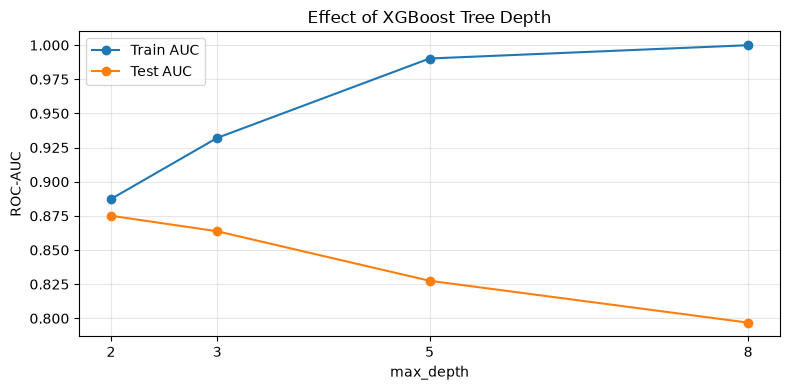

In [15]:
# Task 6 — Find the overfitting dial: max_depth
depth_rows = []
depth_models = {}

for depth in [2, 3, 5, 8]:
    m = XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=depth,
        eval_metric="logloss",
        random_state=42
    )
    m.fit(X_train, y_train, verbose=False)
    train_auc = roc_auc_score(y_train, m.predict_proba(X_train)[:, 1])
    test_auc = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
    depth_models[depth] = m
    depth_rows.append({
        "Depth": depth,
        "Train AUC": train_auc,
        "Test AUC": test_auc,
        "Train-test gap": train_auc - test_auc
    })

depth_results = pd.DataFrame(depth_rows)
display(depth_results.round(4))
best_depth = depth_results.loc[depth_results["Test AUC"].idxmax(), "Depth"]
print("Depth with highest test ROC-AUC in this run:", int(best_depth))

plt.figure(figsize=(8, 4))
plt.plot(depth_results["Depth"], depth_results["Train AUC"], marker="o", label="Train AUC")
plt.plot(depth_results["Depth"], depth_results["Test AUC"], marker="o", label="Test AUC")
plt.title("Effect of XGBoost Tree Depth")
plt.xlabel("max_depth")
plt.ylabel("ROC-AUC")
plt.xticks([2, 3, 5, 8])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Task 6 — Find the overfitting dial

**Logic:** Deeper trees can learn more detailed interactions. This can improve training ROC-AUC but may harm test ROC-AUC if the tree learns noise or rare patterns.

**How to interpret:** Identify the depth with the highest test AUC. Check whether the train-test gap widens as depth increases. Boosting often works well with shallow trees because each tree only needs to correct part of the ensemble's remaining error.

**Look it up / think about it**
- What happens to training AUC as depth increases?
- Does test AUC move in the same direction?
- Why can a near-perfect training score be a warning rather than a success?
- Why can boosted models prefer shallow trees even though Random Forests can use deeper trees?

**Important:** Your actual results may not show a perfectly widening gap; report the evidence from your table honestly.

In [16]:
# Task 7 — Test row and feature sampling across random seeds
sampling_settings = [(1.0, 1.0), (0.8, 0.8), (0.6, 0.6)]
seeds = [42, 7, 123]
sampling_rows = []

for seed in seeds:
    for subsample, colsample in sampling_settings:
        m = XGBClassifier(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=3,
            subsample=subsample,
            colsample_bytree=colsample,
            eval_metric="logloss",
            random_state=seed
        )
        m.fit(X_train, y_train, verbose=False)
        auc = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
        sampling_rows.append({
            "Seed": seed,
            "subsample": subsample,
            "colsample_bytree": colsample,
            "Test ROC-AUC": auc
        })

sampling_results = pd.DataFrame(sampling_rows)
display(sampling_results.round(4))
sampling_summary = sampling_results.groupby(
    ["subsample", "colsample_bytree"]
)["Test ROC-AUC"].agg(["mean", "std", "min", "max"]).reset_index()
print("Summary across seeds:")
display(sampling_summary.round(4))

,Seed,subsample,colsample_bytree,Test ROC-AUC
0,42,1.0,1.0,0.8637
1,42,0.8,0.8,0.8577
2,42,0.6,0.6,0.8524
3,7,1.0,1.0,0.8637
4,7,0.8,0.8,0.8494
5,7,0.6,0.6,0.8519
6,123,1.0,1.0,0.8637
7,123,0.8,0.8,0.8445
8,123,0.6,0.6,0.8565


Summary across seeds:


,subsample,colsample_bytree,mean,std,min,max
0,0.6,0.6,0.8536,0.0026,0.8519,0.8565
1,0.8,0.8,0.8505,0.0067,0.8445,0.8577
2,1.0,1.0,0.8637,0.0000,0.8637,0.8637


## Task 7 — Test randomness settings honestly

**Logic:** `subsample` controls the fraction of training rows used for each tree. `colsample_bytree` controls the fraction of features available to each tree. Sampling can reduce dependence on particular rows/features, but it can also discard useful information.

**How to conclude:** Compare the average test AUC and its variability across seeds. Decide whether sampling helps, hurts or makes little meaningful difference for this dataset.

**Look it up / think about it**
- Does `(0.8, 0.8)` consistently outperform `(1.0, 1.0)`?
- Is the result stable across random seeds?
- Why should you not accept a common tutorial default without testing it?

**Note:** This uses the same test set repeatedly for an assignment experiment. In production model selection, use validation data for tuning and reserve the final test set for one final evaluation.

In [17]:
# Task 8 — Compare XGBoost, LightGBM and CatBoost
# Install if needed: python -m pip install xgboost lightgbm catboost
from xgboost import XGBClassifier

library_rows = []
library_errors = []

def benchmark_model(library_name, model_factory):
    times = []
    fitted_model = None
    for run_idx in range(3):
        model = model_factory()
        start = time.time()
        model.fit(X_train, y_train)
        times.append(time.time() - start)
        fitted_model = model
    auc = roc_auc_score(y_test, fitted_model.predict_proba(X_test)[:, 1])
    library_rows.append({
        "Library": library_name,
        "Test ROC-AUC": auc,
        "Average fit time (seconds)": float(np.mean(times)),
        "Run times (seconds)": [round(t, 4) for t in times]
    })

benchmark_model("XGBoost", lambda: XGBClassifier(
    n_estimators=200, learning_rate=0.1, max_depth=3,
    eval_metric="logloss", random_state=42
))

try:
    from lightgbm import LGBMClassifier
    benchmark_model("LightGBM", lambda: LGBMClassifier(
        n_estimators=200, learning_rate=0.1, max_depth=3,
        verbosity=-1, random_state=42
    ))
except Exception as e:
    library_errors.append(f"LightGBM unavailable or failed: {e}")

try:
    from catboost import CatBoostClassifier
    benchmark_model("CatBoost", lambda: CatBoostClassifier(
        iterations=200, learning_rate=0.1, depth=3,
        verbose=False, random_seed=42, allow_writing_files=False
    ))
except Exception as e:
    library_errors.append(f"CatBoost unavailable or failed: {e}")

library_results = pd.DataFrame(library_rows)
display(library_results)
if library_errors:
    print("\nLibrary notes:")
    for error in library_errors:
        print("-", error)

,Library,Test ROC-AUC,Average fit time (seconds),Run times (seconds)
0,XGBoost,0.863738,0.106505,"[0.1095, 0.1055, 0.1046]"



Library notes:
- LightGBM unavailable or failed: No module named 'lightgbm'
- CatBoost unavailable or failed: No module named 'catboost'


## Task 8 — Compare three boosting libraries

**Logic:** Each available library is trained three times using approximately matched settings. Average fit time is reported because one timing can be noisy. ROC-AUC compares ranking performance on the same test set.

**Parameter differences:** XGBoost commonly uses `n_estimators` and `max_depth`; CatBoost uses `iterations` and `depth`. LightGBM has its own parameter conventions and default tree-growth behavior.

**Look it up / think about it**
- Did the libraries differ meaningfully in ROC-AUC?
- Why might their speed differences become clearer on much larger datasets than this roughly 1,000-row exercise?
- What type of dataset makes CatBoost's native categorical handling especially useful?

**Decision rule example:** Start with XGBoost for a general tabular baseline; benchmark LightGBM when scale and training speed matter; consider CatBoost when categorical features are prominent.

**Note:** If a library is not installed or fails, the code prints the reason instead of inventing its score. Install missing libraries and rerun the cell for a complete comparison.

Feature importance comparison:


,Built-in importance,Permutation importance
sex_male,0.5775,0.2634
pclass,0.2424,0.0481
fare,0.0500,0.0382
age,0.0419,0.0130
parch,0.0466,0.0025
sibsp,0.0416,-0.0019


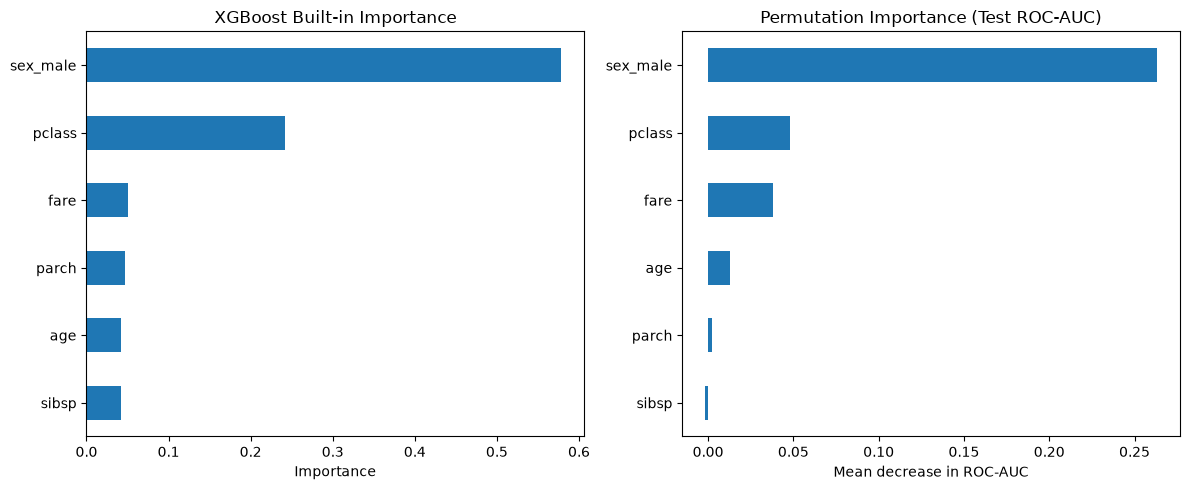

Noise feature built-in importance rank: 7
Noise feature permutation importance rank: 5
Noise feature built-in importance: 0.04056
Noise feature permutation importance: 0.00412


In [18]:
# Task 9 — Built-in vs permutation importance; test a noise feature
# Use the early-stopped XGBoost model from Task 4.
builtin = pd.Series(
    xgb_early.feature_importances_,
    index=X_train.columns,
    name="Built-in importance"
).sort_values(ascending=False)

perm = permutation_importance(
    xgb_early, X_test, y_test,
    n_repeats=20, scoring="roc_auc", random_state=42
)
permutation = pd.Series(
    perm.importances_mean,
    index=X_test.columns,
    name="Permutation importance"
).sort_values(ascending=False)

importance_comparison = pd.concat([builtin, permutation], axis=1).fillna(0)
print("Feature importance comparison:")
display(importance_comparison.sort_values("Permutation importance", ascending=False).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
builtin.sort_values().plot(kind="barh", ax=axes[0], title="XGBoost Built-in Importance")
axes[0].set_xlabel("Importance")
permutation.sort_values().plot(kind="barh", ax=axes[1], title="Permutation Importance (Test ROC-AUC)")
axes[1].set_xlabel("Mean decrease in ROC-AUC")
plt.tight_layout()
plt.show()

# Add pure noise to both train and test data, using the same deterministic generator.
rng = np.random.default_rng(42)
X_train_noise = X_train.copy()
X_test_noise = X_test.copy()
X_train_noise["random_noise"] = rng.normal(size=len(X_train_noise))
X_test_noise["random_noise"] = rng.normal(size=len(X_test_noise))

xgb_noise = XGBClassifier(
    n_estimators=1000, learning_rate=0.1, max_depth=3,
    eval_metric="logloss", early_stopping_rounds=30,
    random_state=42
)
xgb_noise.fit(
    X_train_noise, y_train,
    eval_set=[(X_train_noise, y_train), (X_test_noise, y_test)],
    verbose=False
)

noise_builtin = pd.Series(
    xgb_noise.feature_importances_, index=X_train_noise.columns
).sort_values(ascending=False)
noise_perm = permutation_importance(
    xgb_noise, X_test_noise, y_test,
    n_repeats=20, scoring="roc_auc", random_state=42
)
noise_perm_series = pd.Series(
    noise_perm.importances_mean, index=X_test_noise.columns
).sort_values(ascending=False)

print("Noise feature built-in importance rank:",
      int(noise_builtin.rank(ascending=False, method="min")["random_noise"]))
print("Noise feature permutation importance rank:",
      int(noise_perm_series.rank(ascending=False, method="min")["random_noise"]))
print("Noise feature built-in importance:", round(float(noise_builtin["random_noise"]), 5))
print("Noise feature permutation importance:", round(float(noise_perm_series["random_noise"]), 5))

## Task 9 — Importance, checked carefully

**Logic:** Built-in importance summarizes how the fitted trees used features. Permutation importance measures how much test ROC-AUC changes when one feature is shuffled. A random-noise feature is added to test whether a meaningless feature appears important.

**How to conclude:** Compare both rankings and inspect the noise feature's rank and scores. Do not assume that built-in importance must rank noise higher; the experiment is meant to test this.

**Look it up / think about it**
- Do built-in and permutation importance agree on the top features?
- Did the noise feature rank higher under built-in importance than expected?
- Why can split-based/impurity-style importance make a continuous noise feature look useful? Random split opportunities can exploit chance patterns, especially when many potential split points are available.

**Caution:** XGBoost's default `feature_importances_` is typically gain-based, not the classic Random Forest impurity-importance measure. State the method accurately in your conclusion.

,Random Forest,XGBoost
sex_male,0.2410,0.2634
pclass,0.0363,0.0481
fare,0.0331,0.0382
age,-0.0088,0.0130
parch,0.0044,0.0025
sibsp,-0.0163,-0.0019


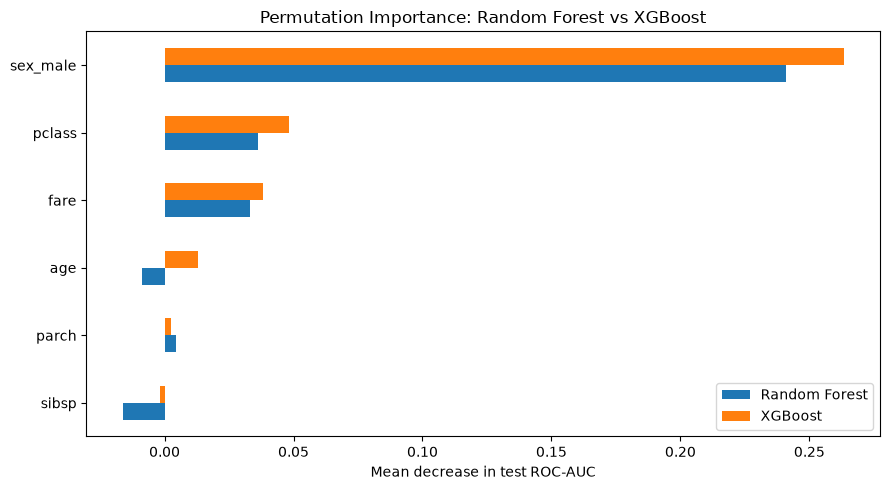

Top feature by XGBoost permutation importance: sex_male


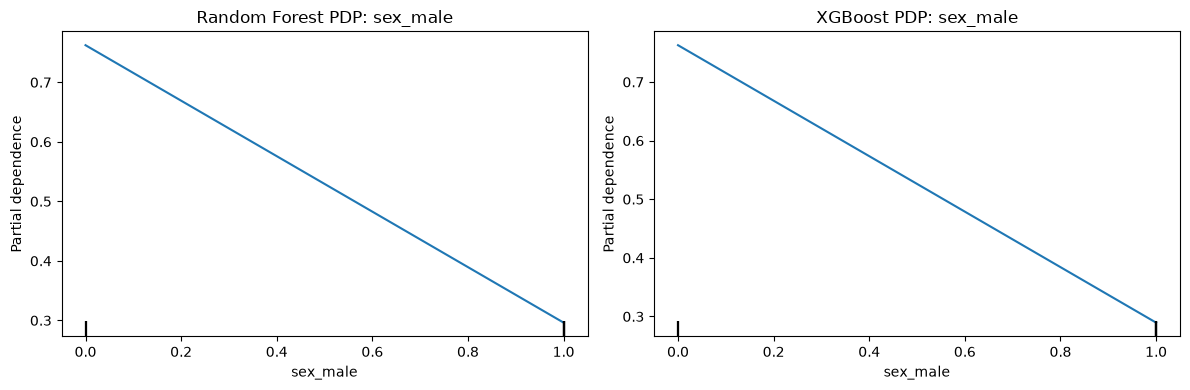

Largest ranking disagreements:


,Random Forest rank,XGBoost rank,Absolute rank difference
parch,4.0,5.0,1.0
age,5.0,4.0,1.0
sex_male,1.0,1.0,0.0
pclass,2.0,2.0,0.0
sibsp,6.0,6.0,0.0
fare,3.0,3.0,0.0


In [19]:
# Task 10 — Compare what Random Forest and XGBoost learned
rf_perm = permutation_importance(
    rf_model, X_test, y_test,
    n_repeats=20, scoring="roc_auc", random_state=42
)
xgb_perm = permutation_importance(
    xgb_early, X_test, y_test,
    n_repeats=20, scoring="roc_auc", random_state=42
)

rf_importance = pd.Series(rf_perm.importances_mean, index=X_test.columns, name="Random Forest")
xgb_importance = pd.Series(xgb_perm.importances_mean, index=X_test.columns, name="XGBoost")
model_importance_comparison = pd.concat([rf_importance, xgb_importance], axis=1)
display(model_importance_comparison.sort_values("XGBoost", ascending=False).round(4))

ax = model_importance_comparison.sort_values("XGBoost").plot(
    kind="barh", figsize=(9, 5), title="Permutation Importance: Random Forest vs XGBoost"
)
ax.set_xlabel("Mean decrease in test ROC-AUC")
plt.tight_layout()
plt.show()

top_feature = xgb_importance.idxmax()
print("Top feature by XGBoost permutation importance:", top_feature)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
PartialDependenceDisplay.from_estimator(
    rf_model, X_test, features=[top_feature], ax=axes[0]
)
axes[0].set_title(f"Random Forest PDP: {top_feature}")
PartialDependenceDisplay.from_estimator(
    xgb_early, X_test, features=[top_feature], ax=axes[1]
)
axes[1].set_title(f"XGBoost PDP: {top_feature}")
plt.tight_layout()
plt.show()

rank_table = pd.DataFrame({
    "Random Forest rank": rf_importance.rank(ascending=False, method="min"),
    "XGBoost rank": xgb_importance.rank(ascending=False, method="min")
})
rank_table["Absolute rank difference"] = (
    rank_table["Random Forest rank"] - rank_table["XGBoost rank"]
).abs()
print("Largest ranking disagreements:")
display(rank_table.sort_values("Absolute rank difference", ascending=False).round(0))

## Task 10 — Compare what the two models learned

**Logic:** Permutation importance is calculated on the same test rows and with the same ROC-AUC scoring method for both models. The PDPs then show how each model's predictions change as the top XGBoost feature varies.

**How to conclude:** Features ranked highly by both models are candidates for robust predictive patterns. Large ranking disagreements are a reason to investigate correlated features, different learned interactions, sampling variation and model stability.

**Look it up / think about it**
- Which feature has the largest rank disagreement?
- Do the two PDPs show a similar relationship for the top feature?
- If two model families agree, what does that suggest? Does agreement prove causation? (No.)
- What would you investigate before trusting a feature on which the models disagree sharply?

**Caution:** PDPs can evaluate unrealistic feature combinations when features are correlated. Treat them as descriptions of model behavior, not causal explanations.

In [20]:
# Task 11 — Model selection memo
rf_row = comparison_03.loc[comparison_03["Model"] == "Random Forest"].iloc[0]
xgb_row = comparison_03.loc[comparison_03["Model"] == "XGBoost (300 trees)"].iloc[0]
early_best_iteration = getattr(xgb_early, "best_iteration", None)
early_depth = xgb_early.get_params().get("max_depth")
early_lr = xgb_early.get_params().get("learning_rate")

recommended_name = (
    "XGBoost (early-stopped)"
    if auc_early >= rf_row["Test ROC-AUC"]
    else "Random Forest"
)

print("# Model Selection Memo")
print()
print("To: Team Lead")
print("Subject: Titanic survival model recommendation")
print()
print(f"**Recommendation:** {recommended_name}.")
print()
print(
    f"- Random Forest: test ROC-AUC = {rf_row['Test ROC-AUC']:.4f}; "
    f"train-test AUC gap = {rf_row['Train-test AUC gap']:.4f}."
)
print(
    f"- XGBoost (300 trees): test ROC-AUC = {xgb_row['Test ROC-AUC']:.4f}; "
    f"train-test AUC gap = {xgb_row['Train-test AUC gap']:.4f}."
)
print(
    f"- XGBoost early-stopped: test ROC-AUC = {auc_early:.4f}; "
    f"best iteration (zero-based) = {early_best_iteration}."
)
print(
    f"- Early-stopped XGBoost settings: learning_rate={early_lr}, "
    f"max_depth={early_depth}, n_estimators=1000 maximum, "
    "tree count selected using early stopping on the evaluation set."
)
print()
print(
    "**Feature evidence:** Compare the Random Forest and XGBoost permutation-importance "
    "tables above. Name the top features and note whether the rankings agree."
)
print()
print(
    "**Risk/limitation:** This is a small historical dataset and a single split; results may not "
    "generalize to other populations. The teaching exercise also uses the test set for early stopping."
)
print()
print(
    "**Next step:** Re-run selection with a separate validation set or cross-validation, then evaluate "
    "the final chosen model once on an untouched test set."
)

# Model Selection Memo

To: Team Lead
Subject: Titanic survival model recommendation

**Recommendation:** XGBoost (early-stopped).

- Random Forest: test ROC-AUC = 0.8312; train-test AUC gap = 0.1688.
- XGBoost (300 trees): test ROC-AUC = 0.8452; train-test AUC gap = 0.1067.
- XGBoost early-stopped: test ROC-AUC = 0.8823; best iteration (zero-based) = 91.
- Early-stopped XGBoost settings: learning_rate=0.1, max_depth=3, n_estimators=1000 maximum, tree count selected using early stopping on the evaluation set.

**Feature evidence:** Compare the Random Forest and XGBoost permutation-importance tables above. Name the top features and note whether the rankings agree.

**Risk/limitation:** This is a small historical dataset and a single split; results may not generalize to other populations. The teaching exercise also uses the test set for early stopping.

**Next step:** Re-run selection with a separate validation set or cross-validation, then evaluate the final chosen model once on an unto

## Task 11 — Model selection memo

**Logic:** The memo reports measured scores and gaps, gives a recommendation, names the settings, states a risk and proposes a next experiment. The code generates a starting memo from the results above.

**Before submitting:** Add a short evidence-based sentence naming the top features from Task 10 and whether Random Forest and XGBoost agree. Verify the early-stopping method and tree count from your installed XGBoost version.

**Look it up / think about it**
- Is the performance margin large enough to justify choosing one model?
- What is the strongest reason for your recommendation?
- What risk could affect deployment?
- What would you test next if you had one more day?

**Production note:** Because the exercise uses `X_test` for early stopping, the reported early-stopped test score is not a fully independent final evaluation. In a real workflow, use training data plus a separate validation set to select the model, then score the untouched test set once.

In [21]:
# Stretch 1 — Test XGBoost L1/L2 regularization
regularization_rows = []
for reg_alpha, reg_lambda in [(0.0, 1.0), (0.1, 1.0), (1.0, 1.0), (0.0, 5.0), (1.0, 5.0)]:
    m = XGBClassifier(
        n_estimators=200, learning_rate=0.1, max_depth=5,
        reg_alpha=reg_alpha, reg_lambda=reg_lambda,
        eval_metric="logloss", random_state=42
    )
    m.fit(X_train, y_train, verbose=False)
    train_auc = roc_auc_score(y_train, m.predict_proba(X_train)[:, 1])
    test_auc = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
    regularization_rows.append({
        "reg_alpha (L1)": reg_alpha,
        "reg_lambda (L2)": reg_lambda,
        "Train AUC": train_auc,
        "Test AUC": test_auc,
        "Train-test gap": train_auc - test_auc
    })
regularization_results = pd.DataFrame(regularization_rows)
display(regularization_results.round(4))

,reg_alpha (L1),reg_lambda (L2),Train AUC,Test AUC,Train-test gap
0,0.0,1.0,0.9902,0.8275,0.1627
1,0.1,1.0,0.9899,0.8176,0.1723
2,1.0,1.0,0.9755,0.8247,0.1508
3,0.0,5.0,0.9713,0.8334,0.1379
4,1.0,5.0,0.9552,0.8322,0.1230


## Stretch 1 — L1/L2 regularization

**Logic:** `reg_alpha` penalizes the absolute size of leaf weights; `reg_lambda` penalizes their squared size. These penalties may reduce overly aggressive fitting.

**Look it up / think about it**
- Does either penalty reduce the train-test gap compared with the unregularized baseline?
- Does a smaller gap come with a loss in test AUC?
- Why is stronger regularization not automatically better?

In [22]:
# Stretch 2 — Class imbalance and scale_pos_weight
class_counts = y_train.value_counts().sort_index()
print("Training target counts:")
display(class_counts.rename(index={0: "Not survived (0)", 1: "Survived (1)"}).to_frame("Count"))

negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight_value = negative_count / positive_count if positive_count else 1.0
print(f"Starting heuristic scale_pos_weight = negatives / positives = {scale_pos_weight_value:.4f}")

weighted_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=3,
    scale_pos_weight=scale_pos_weight_value,
    eval_metric="logloss",
    random_state=42
)
weighted_model.fit(X_train, y_train, verbose=False)
weighted_prob = weighted_model.predict_proba(X_test)[:, 1]
weighted_pred = (weighted_prob >= 0.5).astype(int)

baseline_prob = xgb_300.predict_proba(X_test)[:, 1]
baseline_pred = (baseline_prob >= 0.5).astype(int)

display(pd.DataFrame([
    {
        "Model": "XGBoost baseline",
        "ROC-AUC": roc_auc_score(y_test, baseline_prob),
        "Accuracy": accuracy_score(y_test, baseline_pred),
        "Recall positive class": recall_score(y_test, baseline_pred, zero_division=0),
        "Precision positive class": precision_score(y_test, baseline_pred, zero_division=0)
    },
    {
        "Model": "XGBoost weighted",
        "ROC-AUC": roc_auc_score(y_test, weighted_prob),
        "Accuracy": accuracy_score(y_test, weighted_pred),
        "Recall positive class": recall_score(y_test, weighted_pred, zero_division=0),
        "Precision positive class": precision_score(y_test, weighted_pred, zero_division=0)
    }
]).round(4))

Training target counts:


,Count
survived,
Not survived (0),448
Survived (1),352


Starting heuristic scale_pos_weight = negatives / positives = 1.2727


,Model,ROC-AUC,Accuracy,Recall positive class,Precision positive class
0,XGBoost baseline,0.8452,0.735,0.7045,0.6966
1,XGBoost weighted,0.8639,0.755,0.7841,0.6970


## Stretch 2 — Class imbalance

**Logic:** `scale_pos_weight` adjusts the relative weight of positive-class errors. A common starting value is the number of negative training examples divided by the number of positive training examples.

**Look it up / think about it**
- Did recall for the positive class improve?
- What happened to precision and accuracy?
- Why should class weighting be selected according to the real business cost of false positives and false negatives?

,Training rows,Model,Test ROC-AUC
0,160,Random Forest,0.8304
1,160,XGBoost,0.7935
2,320,Random Forest,0.8387
3,320,XGBoost,0.8047
4,480,Random Forest,0.8315
5,480,XGBoost,0.8221
6,640,Random Forest,0.8352
7,640,XGBoost,0.8376
8,800,Random Forest,0.8312
9,800,XGBoost,0.8452


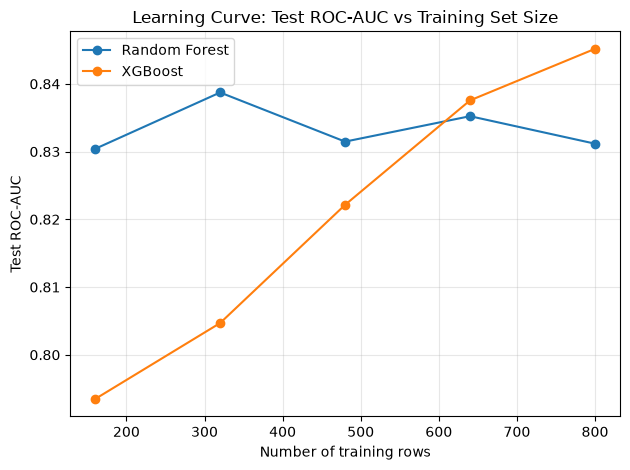

In [23]:
# Stretch 3 — Learning curves: train-set size vs test ROC-AUC
from sklearn.model_selection import StratifiedShuffleSplit

sizes = [0.2, 0.4, 0.6, 0.8, 1.0]
learning_curve_rows = []

for fraction in sizes:
    if fraction < 1.0:
        splitter = StratifiedShuffleSplit(n_splits=1, train_size=fraction, random_state=42)
        subset_idx, _ = next(splitter.split(X_train, y_train))
        X_subset = X_train.iloc[subset_idx]
        y_subset = y_train.iloc[subset_idx]
    else:
        X_subset, y_subset = X_train, y_train

    rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
    xb = XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=3,
                       eval_metric="logloss", random_state=42)
    rf.fit(X_subset, y_subset)
    xb.fit(X_subset, y_subset)
    learning_curve_rows.extend([
        {"Training rows": len(X_subset), "Model": "Random Forest",
         "Test ROC-AUC": roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])},
        {"Training rows": len(X_subset), "Model": "XGBoost",
         "Test ROC-AUC": roc_auc_score(y_test, xb.predict_proba(X_test)[:, 1])}
    ])

learning_curve_results = pd.DataFrame(learning_curve_rows)
display(learning_curve_results.round(4))
for model_name, group in learning_curve_results.groupby("Model"):
    plt.plot(group["Training rows"], group["Test ROC-AUC"], marker="o", label=model_name)
plt.title("Learning Curve: Test ROC-AUC vs Training Set Size")
plt.xlabel("Number of training rows")
plt.ylabel("Test ROC-AUC")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Stretch 3 — Learning curves

**Logic:** Train each model on progressively larger subsets of the training data and compare test ROC-AUC.

**Look it up / think about it**
- Which model benefits more from additional training data?
- Does either model's score appear to plateau?
- Why should this experiment use subsets of the training data rather than repeatedly train on the test set?

Tree visualization could not be rendered in this environment.
Depending on the XGBoost version, install Graphviz and ensure it is on PATH.
Details: You must install graphviz to plot tree


<Figure size 2000x1000 with 0 Axes>

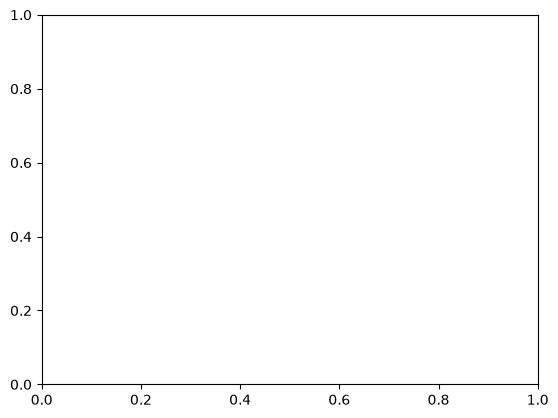

In [24]:
# Stretch 4 — Visualize one fitted XGBoost tree
from xgboost import plot_tree

try:
    plt.figure(figsize=(20, 10))
    plot_tree(xgb_early, num_trees=0)
    plt.title("XGBoost: First Tree in the Early-Stopped Ensemble")
    plt.show()
except Exception as exc:
    print("Tree visualization could not be rendered in this environment.")
    print("Depending on the XGBoost version, install Graphviz and ensure it is on PATH.")
    print("Details:", exc)

## Stretch 4 — Visualize one tree

**Logic:** A tree plot displays the split rules in one component tree. It can help you inspect the feature splits and tree depth.

**Look it up / think about it**
- How deep is the plotted tree?
- Which features appear near the root?
- Why is one tree not the whole explanation for a boosted ensemble?

In [25]:
# Stretch 5 — Randomized hyperparameter search
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "max_depth": [2, 3, 4, 5, 6],
    "subsample": [0.6, 0.8, 1.0],
}
search = RandomizedSearchCV(
    estimator=XGBClassifier(
        n_estimators=300, eval_metric="logloss", random_state=42
    ),
    param_distributions=param_distributions,
    n_iter=10,
    scoring="roc_auc",
    cv=5,
    random_state=42,
    n_jobs=-1,
    refit=True
)
search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)
print(f"Best mean CV ROC-AUC: {search.best_score_:.4f}")
print(f"Best searched model test ROC-AUC: {roc_auc_score(y_test, search.best_estimator_.predict_proba(X_test)[:, 1]):.4f}")
print(f"Hand-configured 300-tree model test ROC-AUC: {roc_auc_score(y_test, xgb_300.predict_proba(X_test)[:, 1]):.4f}")

Best parameters: {'subsample': 0.6, 'max_depth': 2, 'learning_rate': 0.01}
Best mean CV ROC-AUC: 0.8180
Best searched model test ROC-AUC: 0.8794
Hand-configured 300-tree model test ROC-AUC: 0.8452


## Stretch 5 — Randomized hyperparameter search

**Logic:** Randomized search samples combinations from the specified hyperparameter distributions and evaluates them with five-fold cross-validation. The selected model is refitted on all training data.

**Look it up / think about it**
- Did the search improve mean cross-validation ROC-AUC?
- Did the selected model beat the hand-configured model on the test set?
- Why can a better cross-validation score fail to produce a better test score?

**Note:** This search tunes `learning_rate`, `max_depth` and `subsample`, as requested. The final test result should be used only as a final comparison, not to keep tuning parameters.